# 太平洋变暖，大西洋如何响应？
## ENSO 与北大西洋风暴数量、路径构成和空间分布的可复现分析

**ENSO Storm Atlas · Academic notebook**  
中文研究叙述 · English figure labels · 1950–2025 数据档案 · 1966–2025 主分析

这份 Notebook 将交互式图谱中的观察组织成一条统计证据链：**季节活动强度 → 路径类型构成 → 质心偏移的来源 → 单条路径包含的信息**。图、表和结果段落均在运行时由固定数据快照生成；已提交的输出来自一次完整执行。

研究对象是北大西洋达到热带风暴强度的系统。本文的“风暴”包含热带风暴与飓风；“美国登陆风暴数”指满足数据处理规则的不同风暴数，而非登陆事件次数。

**阅读路径**：先读第 1 节的问题和第 2 节的数据定义，再按图 1–7 阅读结果；第 9 节将结论与证据逐项连接。要重新计算，在安装 `requirements-notebook.txt` 后执行仓库根目录下的 `python scripts/run_research_notebook.py`。

## 1. 研究背景：从“风暴少了”到“哪些路径少了”

厄尔尼诺—南方涛动（El Niño–Southern Oscillation，ENSO）把热带太平洋的海温变化与大尺度大气环流联系起来。NOAA 对飓风季的说明指出，厄尔尼诺通常增强大西洋的垂直风切变，使热带气旋的形成和维持条件发生变化 [1]。这一物理背景引出了一个可直接用历史记录回答的问题：**不同 ENSO 位相下，北大西洋风暴活动的数量与空间分布有何差异？**

季节总数只能描述活动强弱，不能说明减少的风暴原本会走哪条路线。假如墨西哥湾—加勒比型路径占比下降，即使每一种路径的形态都保持不变，全体风暴的平均位置也会向东移动。反过来，即使类型占比不变，同一类型的路径向北偏移也会改变全体质心。因此，需要把**类型构成变化**与**类内位置变化**分开。

质量矩提供了连接路径和统计量的简洁方式。Nakamura 等以路径的质心、方差和协方差描述北大西洋热带气旋，并研究了这些量在路径分类中的作用 [2]。本分析沿用质量矩描述位置和离散程度，以等距重采样的路径进行聚类，再检验偏度、峰度是否在低阶矩之外提供判别信息。

### 研究问题与证据结构

| 问题 | 统计对象与对比 | 对应证据 |
|---|---|---|
| Q1：季节活动是否随 ENSO 位相变化？ | 拉尼娜减厄尔尼诺的年均风暴数、ACE、美国登陆风暴数 | 图 1–2；整季置换与季节 bootstrap |
| Q2：差异集中在哪些路径？ | 四类路径每年的发生数，以及各类占全部风暴的比例 | 图 3；四项发生率对比的 Holm 校正 |
| Q3：整体东移、北移分别从何而来？ | 厄尔尼诺减拉尼娜的风暴平均质心；构成项与类内项 | 图 4；精确代数分解和成组重采样 |
| Q4：分解是否依赖人为设定？ | K=3–7、纬度去趋势、时期和强度门槛、逐季剔除 | 图 5；敏感性结果表 |
| Q5：单条路径能否识别季节位相？ | 按年份分组的交叉验证 AUC；加入偏度和峰度后的配对增益 | 图 6–7；标签置换零分布与 bootstrap 区间 |

这是对历史季节的关联分析。数量、空间分布和分类三部分回答不同问题，统一使用季节作为重采样的单位。

## 2. 数据、术语与可复现入口

路径来自 NOAA NCEI 的 IBTrACS v04r01 北大西洋档案 [3]，ENSO 指标来自 NOAA CPC 的 ONI [4]。随本 Notebook 提交的快照与网站的数据包一致；`data/manifest.json` 记录来源 URL、源代码提交、文件 SHA-256 和原始下载文件的校验和。海岸线由 Natural Earth / world-atlas 提供 [5]。

| 术语 | 本文的固定定义 |
|---|---|
| ONI | Niño 3.4 区域三个月海温距平；使用每年 8–10 月（ASO）的数值 |
| ENSO 位相 | ASO ONI ≥ +0.5°C 为厄尔尼诺，≤ −0.5°C 为拉尼娜，其余为中性年；这是季节分组规则，不是连续五季的事件判定 |
| 风暴样本 | 1950–2025 年、`main` 或 `PROVISIONAL` 路径中，至少有一个热带／副热带定位点的 `USA_WIND` ≥34 kt 的系统 |
| 路径 | 从首次达到上述条件的定位点到记录终点，保留其后的完整轨迹，包括转变为温带系统后的定位点；经纬度在快照中保留 0.1° |
| ACE | 对热带／副热带且风速 ≥34 kt 的 6 小时定位点计算 $10^{-4}\sum v_t^2$；季节 ACE 为风暴 ACE 之和 |
| 美国登陆风暴 | 至少一次 `LANDFALL=0`、风速 ≥34 kt 的定位点落入所选美国本土多边形附近的风暴；沿用网站的 0.05° 多边形容差，不把多次登陆重复计数 |
| 路径质心 | 每条路径所有定位点经纬度的算术平均；比较两组时每条风暴的权重相同 |
| 类型构成 | 某类风暴占该 ENSO 位相所有风暴的比例；与“每年多少条”分别计算 |
| AUC | ROC 曲线下面积；表示样本排序的区分能力，不是分类正确率 |

主分析窗口为 **1966–2025**，以减少早期海上短生命风暴漏报的影响，同时保持与网页一致。1950–2025 和 1980–2025 用于时期敏感性检验。风暴是否属于某一 ENSO 位相，仅由其所属年份的 ASO ONI 决定。

原始数据处理可通过仓库中的 `download_data.py` 和 `build_data.py` 重新执行。下面从**带校验和的已处理快照**开始，重新计算全部统计结果，不读取网站已有的 AUC 或分解结果。原始数据日后修订时，可以重建一个新快照，但应保留版本以区分数据更新与方法变化。

In [1]:
import os
for variable in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS'):
    os.environ[variable] = '1'
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
%matplotlib inline

HERE = Path.cwd()
NOTEBOOK_DIR = HERE if (HERE / 'atlas_analysis.py').exists() else HERE / 'notebooks'
sys.path.insert(0, str(NOTEBOOK_DIR))
import atlas_analysis as aa

d, years, storms, tracks, features, season, cohorts = aa.load_data()
display(cohorts)
display(Markdown(f"**数据校验通过。** 档案含 {len(storms)} 条风暴路径和 {len(years)} 个季节；"
                 f"1966–2025 年含 {int((storms.y >= 1966).sum())} 条路径。"
                 "风暴 ID 唯一、位相阈值一致，打包风速重算的 ACE 与快照的差值处于逐风暴四舍五入误差内。"))

,start,phase,seasons,storms,finite_nine_moments
0,1950,nina,18,284,284
1,1950,neutral,38,476,472
2,1950,nino,20,219,219
3,1966,nina,14,226,226
4,1966,neutral,31,399,395
5,1966,nino,15,165,165
6,1980,nina,10,175,175
7,1980,neutral,24,324,320
8,1980,nino,12,127,127


**数据校验通过。** 档案含 979 条风暴路径和 76 个季节；1966–2025 年含 790 条路径。风暴 ID 唯一、位相阈值一致，打包风速重算的 ACE 与快照的差值处于逐风暴四舍五入误差内。

### 推断设计

同一年内的风暴共享大尺度环境；不能把它们当作独立的 ENSO 暴露样本。所有置换在**整年之间交换位相标签**，保留每年的全部风暴；所有 bootstrap 在两个位相内分别有放回抽取整年。季节活动对比以每个年份等权；质心和矩对比以风暴等权，但重采样仍以年份为单位。

- 季节活动、路径类型发生率与九个矩：9,999 次双侧置换；季节活动和类型发生率的区间使用 5,000 次季节 bootstrap。
- 主质心分解：3,999 次双侧置换和 2,000 次季节 bootstrap；对总差异、构成项、类内项的经纬度共六项检验进行 Holm 校正。
- 检验族：三个季节活动指标、四个路径发生率分别做 Holm 校正；九个矩与六组分类特征分别报告 Benjamini–Hochberg（BH）FDR。稳健性面板用于观察设定变化，单独列出未校正的置换 p 值。
- 分类模型：10 次随机分折，每次 10 折、整年留出；199 次整季标签置换；高阶矩增益使用 200 次整季 bootstrap。所有随机种子写在代码中。

$p=(b+1)/(B+1)$，其中 $b$ 为至少与观察统计量同样极端的置换数。除 AUC 的单侧“高于零分布”检验外，其余置换均为双侧。区间均为 percentile bootstrap 95% 区间；未对区间另做同时覆盖率校正。置换推断以所比较年份在零假设下可交换为工作假设。

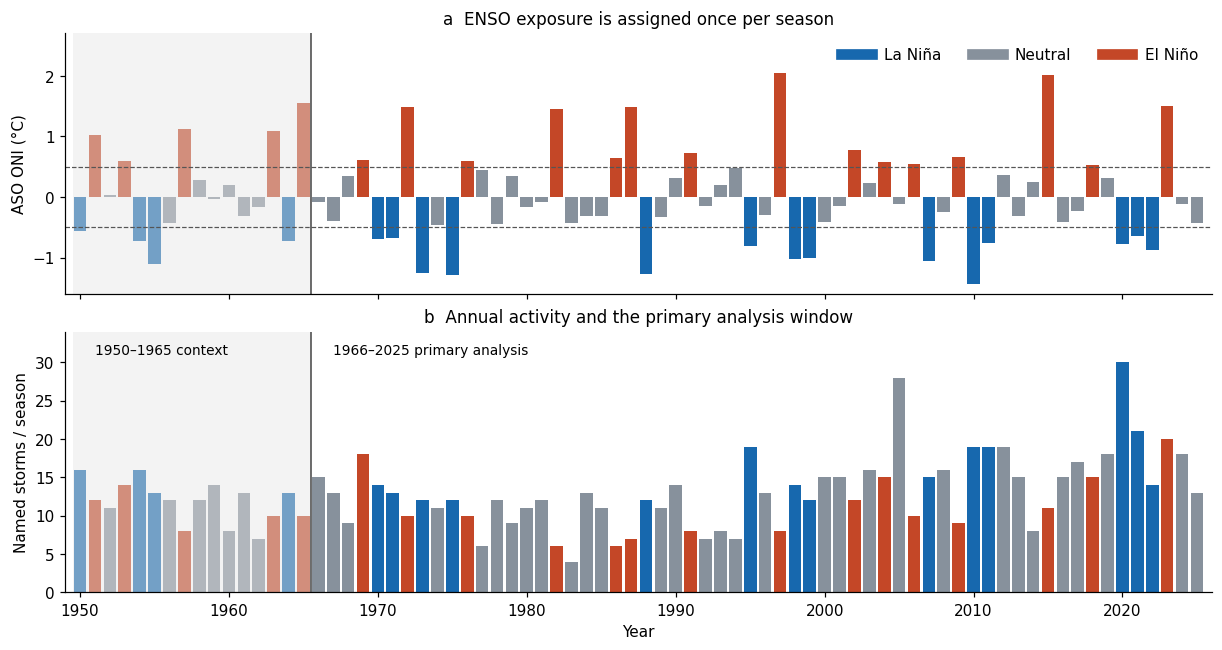

In [2]:
aa.fig_context(season)

**图 1｜以季节为单位连接 ENSO 与风暴记录。** 上图为 ASO ONI，下图为每年达到样本门槛的风暴数；暖色、灰色和蓝色分别表示厄尔尼诺、中性年和拉尼娜。灰色背景为 1966 年以前的历史资料。季节是暴露和推断单位，风暴是路径分析的观测单位。

时间序列既展示相邻年份间的变化，也说明为什么需要阶段性对比和敏感性分析：整段记录的气候背景与观测能力并非完全相同。

## 3. 数量层面：太平洋暖位相对应怎样的大西洋活动？

首先检验三个直接描述季节活动的指标。对每个指标定义

$$\Delta_{\mathrm{activity}}=\overline{Y}_{\mathrm{La\ Niña}}-\overline{Y}_{\mathrm{El\ Niño}}.$$

这一方向与“拉尼娜年是否更活跃”的问题一致。使用全部风暴而非只选择飓风，可以同时观察生成数量和积分强度的变化。中性年在图中作为背景组展示，但不进入两位相的主要假设检验。

,outcome,nina_mean,nino_mean,delta_nina_minus_nino,ci_low,ci_high,p_permutation,p_holm
0,storms,16.1429,11.0000,5.1429,2.0142,8.5051,0.0055,0.0165
1,ace,128.6729,80.7707,47.9022,8.5846,85.2546,0.0267,0.0267
2,us,4.2857,2.2667,2.0190,0.6333,3.4525,0.0086,0.0172


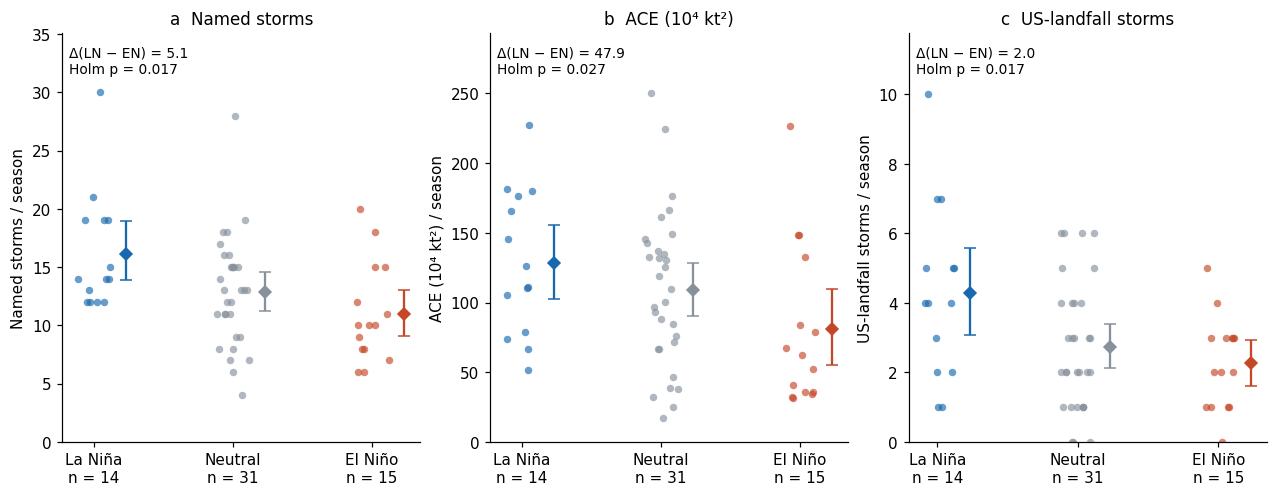

- **风暴数**：拉尼娜 16.14，厄尔尼诺 11.00；年均差 5.14，95% CI [2.01, 8.51]，Holm 校正 p=0.0165。
- **ACE**：拉尼娜 128.67，厄尔尼诺 80.77；年均差 47.90，95% CI [8.58, 85.25]，Holm 校正 p=0.0267。
- **美国登陆风暴数**：拉尼娜 4.29，厄尔尼诺 2.27；年均差 2.02，95% CI [0.63, 3.45]，Holm 校正 p=0.0172。

In [3]:
activity = aa.seasonal_results(season)
display(activity.round(4))
aa.fig_activity(season, activity)
lines = []
for _, r in activity.iterrows():
    name = {'storms': '风暴数', 'ace': 'ACE', 'us': '美国登陆风暴数'}[r.outcome]
    lines.append(f"- **{name}**：拉尼娜 {r.nina_mean:.2f}，厄尔尼诺 {r.nino_mean:.2f}；"
                 f"年均差 {r.delta_nina_minus_nino:.2f}，95% CI [{r.ci_low:.2f}, {r.ci_high:.2f}]，"
                 f"Holm 校正 p={r.p_holm:.4f}。")
display(Markdown('\n'.join(lines)))

**图 2｜季节活动的三个互补指标。** 小圆点表示单个季节，菱形和误差线表示季节均值及 95% bootstrap 区间。标签给出拉尼娜减厄尔尼诺的年均差及三项检验的 Holm 校正 p 值。美国指标按不同风暴计数；ACE 反映风速平方随时间累积的活动强度。

三个指标从数量、积分强度和美国本土附近的登陆风暴数描述同一组季节。下一步不把整体差异直接归结为每条风暴都减弱，而是问：**哪一类路径的发生频率改变最大？**

## 4. 构成层面：减少的风暴原本走哪条路径？

对每条路径，以沿轨迹累计距离近似量进行线性插值，得到 16 个等距位置。累计距离使用 $x=\lambda\cos\phi$、$y=\phi$ 的相邻点距离；聚类向量为 16 个经度和 16 个纬度，经度统一乘 $\cos25^\circ$。这一设定保留生成位置、路径走向和空间跨度，避免按位相分别聚类导致类型定义不一致。

网站的四类标签由 1950–2025 全部路径的单一 K-Means 模型确定；各位相共用同一类型定义。下方重新拟合 K=3–7 检查轮廓系数，同时继续使用固定的网站标签作为主分解。由于快照坐标保留至 0.1°、重拟合初始化次数也与最终网站拟合不同，重新拟合的标签可能有少量差别，因此同时给出调整 Rand 指数（ARI）。聚类仅用于描述路径群体；分类评估不把全体样本聚类标签作为预测变量。

,K,silhouette
0,3,0.3239
1,4,0.3619
2,5,0.3374
3,6,0.2859
4,7,0.2750


重拟合 K=4 与固定网站标签的 **ARI = 1.000**。

,type,nina_mean,nino_mean,delta_nina_minus_nino,ci_low,ci_high,p_permutation,p_holm
0,Gulf & Caribbean,5.9286,2.3333,3.5952,2.1333,5.2000,0.0002,0.0008
1,East Coast recurver,4.2857,3.2000,1.0857,-0.0477,2.2668,0.1092,0.3276
2,Mid-Atlantic recurver,3.1429,2.9333,0.2095,-1.0144,1.4335,0.7553,1.0000
3,Cape Verde type,2.7857,2.5333,0.2524,-1.3955,1.7764,0.8131,1.0000


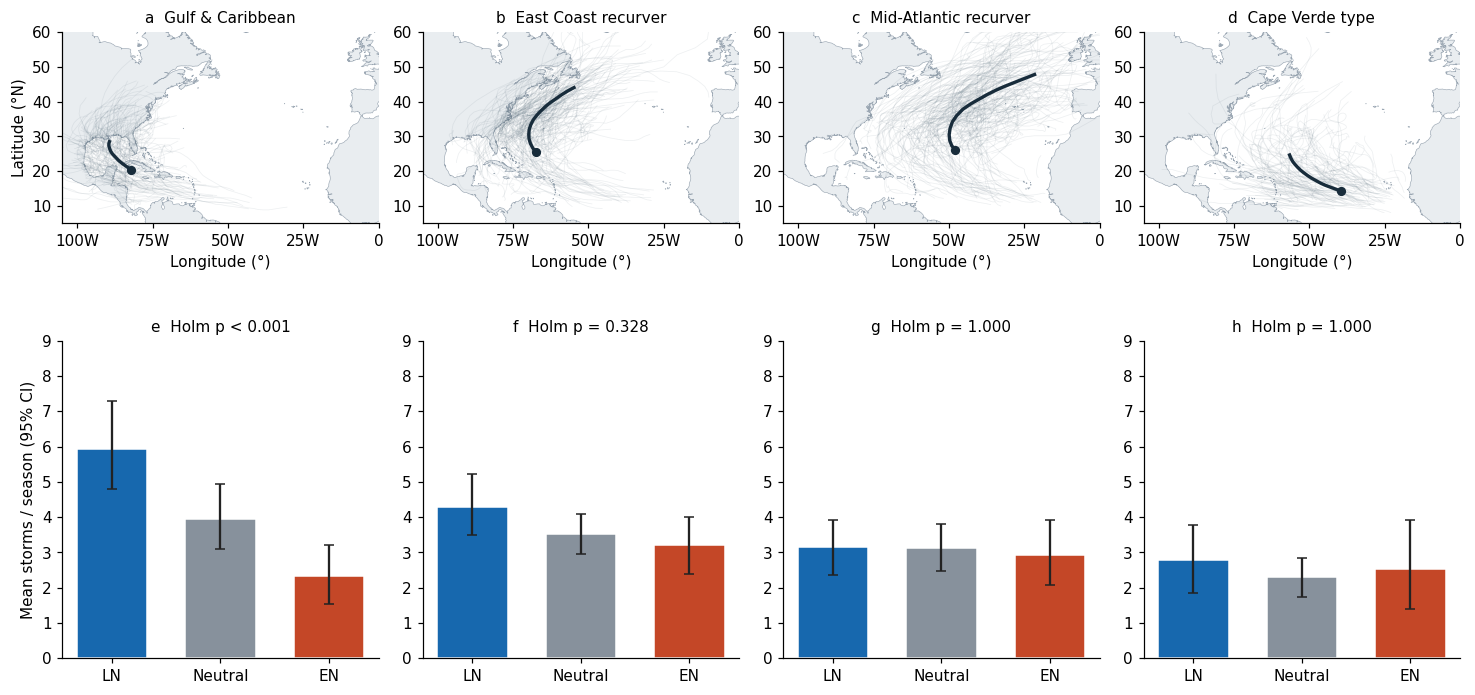

墨西哥湾—加勒比型年均路径数为拉尼娜 **5.93**、厄尔尼诺 **2.33**；差值 **3.60** 占总风暴数差值的 **69.9%**。四类发生率比较的 Holm 校正 p=0.0008。

In [4]:
fits, type_rates, cluster_selection, cluster_ari = aa.cluster_results(storms, features, season)
display(cluster_selection.round(4))
display(Markdown(f"重拟合 K=4 与固定网站标签的 **ARI = {cluster_ari:.3f}**。"))
display(type_rates.round(4))
aa.fig_types(storms, tracks, features, season, type_rates)
r = type_rates.iloc[0]
activity_delta = activity.loc[activity.outcome == 'storms', 'delta_nina_minus_nino'].iloc[0]
display(Markdown(f"墨西哥湾—加勒比型年均路径数为拉尼娜 **{r.nina_mean:.2f}**、厄尔尼诺 **{r.nino_mean:.2f}**；"
                 f"差值 **{r.delta_nina_minus_nino:.2f}** 占总风暴数差值的 **{r.delta_nina_minus_nino/activity_delta:.1%}**。"
                 f"四类发生率比较的 Holm 校正 p={r.p_holm:.4f}。"))

**图 3｜同一套路径类型揭示数量差异的来源。** 上排细线为 1966–2025 年各类轨迹，粗线为重采样路径的逐位置均值，圆点标出平均起点。下排为三种 ENSO 位相中每年各类风暴数，误差线为季节 bootstrap 95% 区间；LN、EN 分别表示拉尼娜和厄尔尼诺。

年均数量下降与类型占比下降不是同一个命题。前者回答“少了多少条”，后者回答“总体由哪些路径组成”。为了讨论全体质心为何移动，下一节使用**各类占所有风暴的比例**，而非年均数量作为分解权重。

## 5. 空间层面：东移来自构成变化，北移来自哪里？

每条路径的质心为其各定位点经纬度的算术平均。令 $p_k^E,p_k^L$ 表示两位相中第 $k$ 类的风暴比例，$\mu_k^E,\mu_k^L$ 表示该类风暴质心的平均值。全体平均质心差可精确写成

$$\begin{aligned}
\Delta\mu &= \sum_k p_k^E\mu_k^E-\sum_k p_k^L\mu_k^L\\
&=\underbrace{\sum_k(p_k^E-p_k^L)\frac{\mu_k^E+\mu_k^L}{2}}_{\text{type mix：类型构成项}}
+\underbrace{\sum_k\frac{p_k^E+p_k^L}{2}(\mu_k^E-\mu_k^L)}_{\text{within type：类内位置项}}.
\end{aligned}$$

这是使用平均权重的对称恒等分解，不依赖指定一个位相作为基准。经度、纬度分别计算，正值表示厄尔尼诺相对拉尼娜偏东或偏北。代码逐次验证“总差异 = 构成项 + 类内项”，再用整季重采样为每个分量构建区间和 p 值。若某次重采样导致某一位相缺少某个类型，程序显式报错，而不把未定义的类内均值填为零。

,axis,component,estimate,ci_low,ci_high,p_permutation,K,start,detrended,p_holm
0,longitude,total,6.6562,3.4034,9.9907,0.0005,4,1966,False,0.0030
1,longitude,type_mix,5.8493,2.5812,9.4431,0.0025,4,1966,False,0.0112
2,longitude,within_type,0.8069,-0.7095,2.3784,0.3470,4,1966,False,0.6940
3,latitude,total,2.2182,0.5905,3.9185,0.0145,4,1966,False,0.0435
4,latitude,type_mix,0.6378,-0.8435,2.0572,0.3792,4,1966,False,0.6940
5,latitude,within_type,1.5803,0.6549,2.5300,0.0022,4,1966,False,0.0112


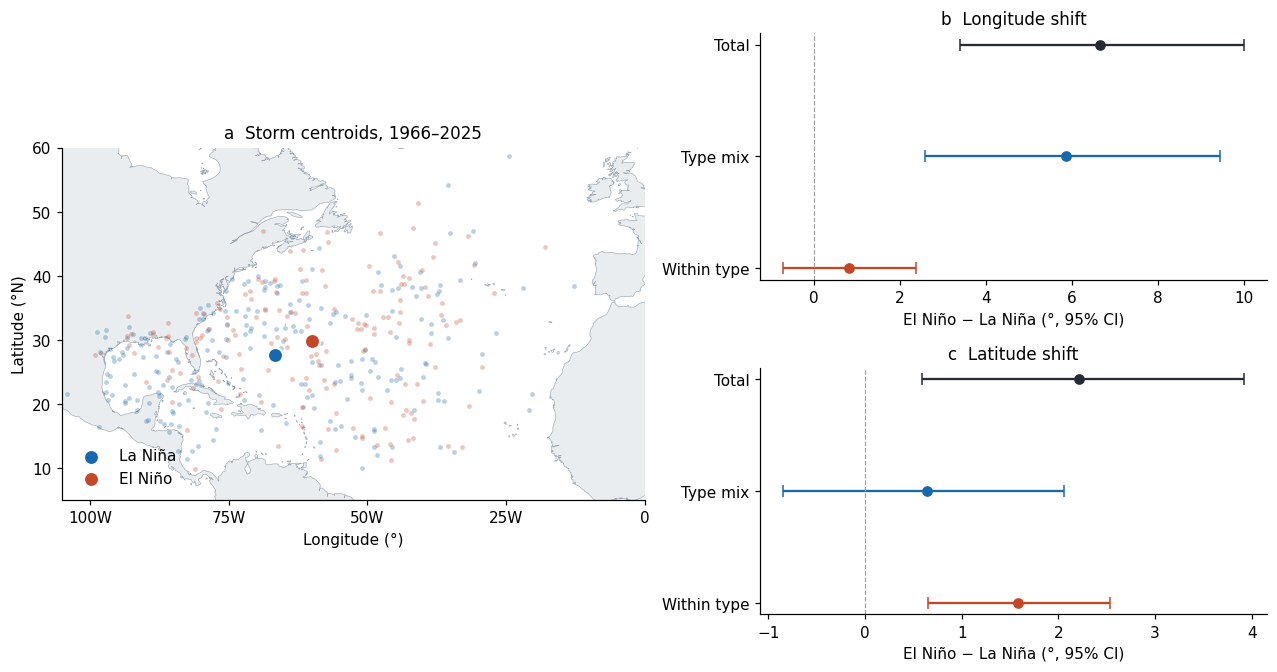

**东西向**：总差异 6.66°；构成项 5.85°，类内项 0.81°。

**南北向**：总差异 2.22°；构成项 0.64°，类内项 1.58°。

In [5]:
decomposition = aa.decompose(storms, storms.k)
aa.write_table(decomposition, 'centroid_decomposition')
display(decomposition.round(4))
aa.fig_decomposition(storms, decomposition)
for axis, name in [('longitude', '东西向'), ('latitude', '南北向')]:
    t = decomposition.query('axis == @axis').set_index('component')
    display(Markdown(f"**{name}**：总差异 {t.loc['total','estimate']:.2f}°；"
                     f"构成项 {t.loc['type_mix','estimate']:.2f}°，类内项 {t.loc['within_type','estimate']:.2f}°。"))

**图 4｜质心差异的精确分解及季节抽样不确定性。** 左图小点为单条风暴质心，大点为位相均值；右图分别展示经度、纬度的总差异、类型构成项和类内位置项。误差线为整季 bootstrap 95% 区间。统计表同时给出六项置换检验的原始 p 值及 Holm 校正值。

分解把“地图上的平均位置变了”转为两个可单独检验的问题：一是类型比例是否改变，二是同类风暴的位置是否改变。东移的主导分量是类型构成；对北移则需要结合类内分量和以下敏感性分析判断。

## 6. 稳健性：结论是否由类型数量或少数季节决定？

这里改变三组分析设定。第一，K=3–7 均重新拟合路径类型，观察东移构成项与北移类内项是否保持方向。第二，在所有 1966–2025 风暴上回归纬度质心与年份，移除线性趋势后，再比较两位相。第三，把起始年改为 1950、1966、1980，并分别纳入全部风暴、飓风和强飓风，重新估计每年的风暴数量差。

另外逐一剔除 29 个非中性季节中的一个，重新计算总体质心差。逐季剔除描述的是单个季节对点估计的影响，不是另一组独立重复实验。K 值稳健性图给出未校正的置换 p 值，便于比较设定；它不替代主分析的成组检验。

,model,axis,component,estimate,p_permutation
0,K = 3,longitude,total,6.6562,0.001
1,K = 3,longitude,type_mix,6.4990,0.001
2,K = 3,longitude,within_type,0.1573,0.860
3,K = 3,latitude,total,2.2182,0.011
4,K = 3,latitude,type_mix,0.9096,0.001
5,K = 3,latitude,within_type,1.3086,0.125
6,K = 4,longitude,total,6.6562,0.001
7,K = 4,longitude,type_mix,5.8493,0.001
8,K = 4,longitude,within_type,0.8069,0.336
9,K = 4,latitude,total,2.2182,0.011


,start,min_category,delta_storms_per_year,ci_low,ci_high,p
0,1950,0,4.8278,2.3110,7.4279,0.0010
1,1950,1,2.9167,1.3722,4.4833,0.0025
2,1950,3,1.7278,0.8889,2.5168,0.0010
3,1966,0,5.1429,2.0235,8.8051,0.0082
4,1966,1,3.0048,1.1470,4.9381,0.0082
5,1966,3,1.6381,0.5857,2.6144,0.0070
6,1980,0,6.9167,2.9829,10.9842,0.0035
7,1980,1,4.1333,2.0833,6.0833,0.0012
8,1980,3,2.0000,0.8496,3.0167,0.0058


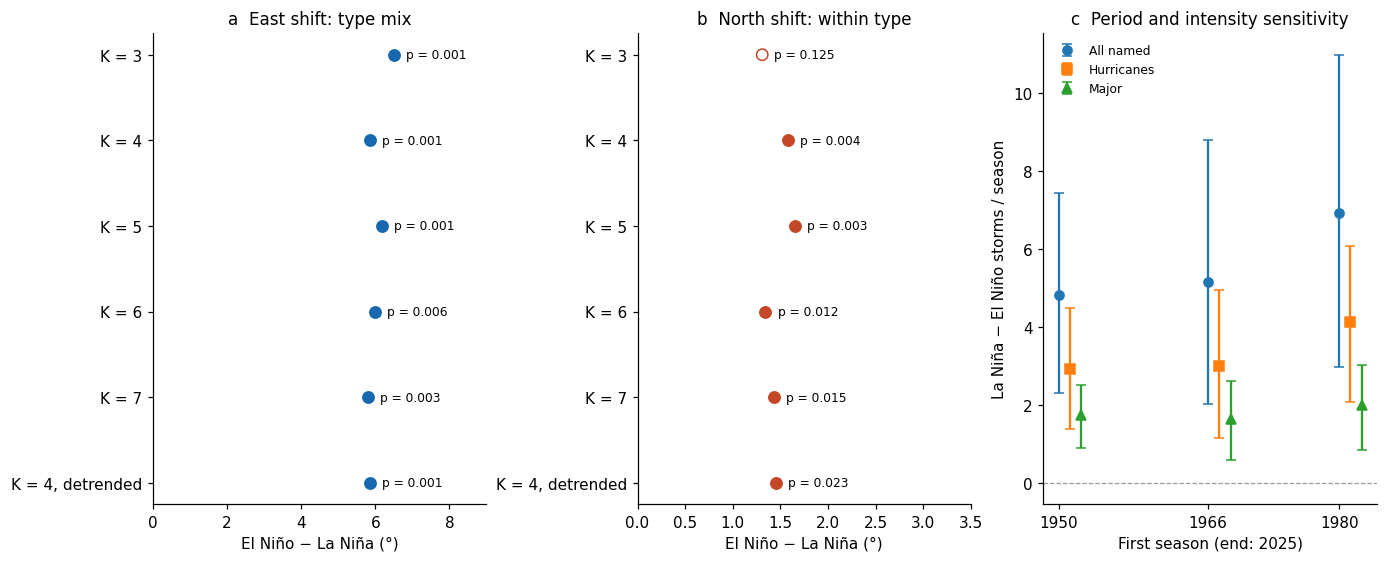

,min,max
axis,,
latitude,1.845,2.587
longitude,5.767,7.695


**北移类内项的设定依赖性：** K = 3: 1.31°，p=0.125；K = 4: 1.58°，p=0.004；K = 5: 1.65°，p=0.003；K = 6: 1.34°，p=0.012；K = 7: 1.43°，p=0.015；K = 4, detrended: 1.45°，p=0.023。

In [6]:
robust, sensitivity, leave_one_out = aa.robustness(storms, fits, season)
display(robust[['model','axis','component','estimate','p_permutation']].round(4))
display(sensitivity.round(4))
aa.fig_robustness(robust, sensitivity)
display(leave_one_out.groupby('axis').estimate.agg(['min','max']).round(3))
north = robust.query('axis == "latitude" and component == "within_type"')
display(Markdown("**北移类内项的设定依赖性：** " + '；'.join(
    f"{r.model}: {r.estimate:.2f}°，p={r.p_permutation:.3f}" for r in north.itertuples()) + '。'))

**图 5｜改变类型数、时期与强度门槛。** a、b 为不同 K 和去趋势后的构成／类内分量，标签为 999 次整季置换 p 值；这些点是不同模型设定下的估计，不是置信区间。c 为不同起始年份和强度门槛下的年均风暴数差，误差线为 2,000 次季节 bootstrap 95% 区间。

东移与类型构成的联系在各 K 值下保持。北移的类内解释在 K≥4 以及线性去趋势后得到支持，K=3 的分类较粗时支持较弱。因此，空间变化中最稳定的部分是“哪些路径进入总体”的变化；北移还包含同类路径位置的变化，其检验强度取决于类型分辨率。

## 7. 形状层面：用九个矩描述路径

对一条包含 $n$ 个定位点的路径，令 $x_i,y_i$ 为经纬度，则一阶矩为 $\bar x,\bar y$；二阶矩采用分母 $n-1$ 的样本方差与协方差。偏度定义为 $m_3/m_2^{3/2}$，超额峰度定义为 $m_4/m_2^2-3$，其中 $m_j=n^{-1}\sum_i(x_i-\bar x)^j$，纬度同理。偏度、峰度采用 SciPy 默认的 `bias=True` 估计，与网页分类输入一致。

九个矩为：质心经纬度、经纬度方差、协方差、经纬度偏度与超额峰度。少于四个定位点或矩不有限的路径不进入九矩分析。它们描述**定位点的空间分布**；例如纬度右偏说明分布向北延伸，不能仅据此推出路径何时开始北上。

这里以厄尔尼诺减拉尼娜的风暴均值差作为统计量，对九个矩进行整年标签置换并报告 BH q 值。密度曲线仅用于展示分布重叠；同一风暴中的定位点不被当作独立的检验样本。

,moment,delta_nino_minus_nina,p_permutation,q_bh
0,Ex,6.65622,0.0002,0.00180
1,Ey,2.21817,0.0142,0.03802
2,Vx,28.29596,0.0945,0.12150
3,Vy,-0.00579,0.9996,0.99960
4,Cxy,13.58299,0.0689,0.10335
5,Sx,0.04886,0.4922,0.55372
6,Sy,-0.16261,0.0169,0.03802
7,Kx,0.22745,0.0547,0.09846
8,Ky,-0.19108,0.0060,0.02700


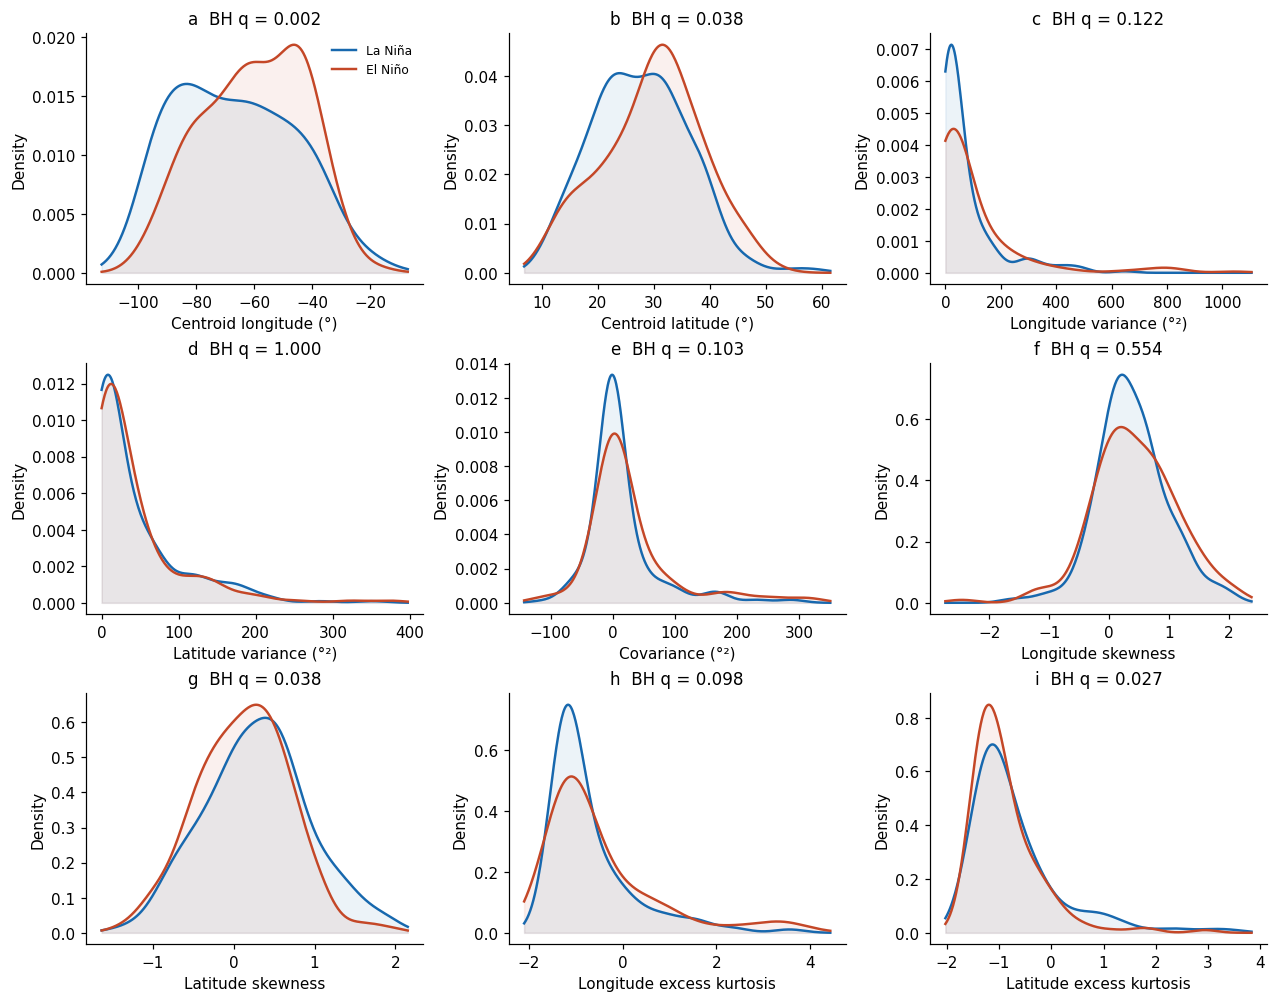

九项比较经 BH 校正后 q<0.05 的矩：**Ex、Ey、Sy、Ky**。

In [7]:
moment_table = aa.moment_results(storms)
display(moment_table.round(5))
aa.fig_moments(storms, moment_table)
selected = moment_table.loc[moment_table.q_bh < .05, 'moment'].tolist()
display(Markdown('九项比较经 BH 校正后 q<0.05 的矩：**' + '、'.join(selected) + '**。'))

**图 6｜路径矩的分布与多重比较。** 蓝色为拉尼娜，暖色为厄尔尼诺；曲线采用 Gaussian KDE、Scott 带宽规则，展示全部观测范围及轻微外延，方差面板的横轴限定为非负。每个面板标注对九项整年置换检验作 BH 校正后的 q 值。经纬度、方差、偏度与峰度具有不同单位，分别展示而不把雷达面积解释为综合效应。

组均值差异与个体可判别性不是同一件事：两组高度重叠的分布仍可能有稳定的均值差。下一节直接用留出年份中的风暴检验单条路径携带的信息。

## 8. 判别层面：单条路径的信息有多强，高阶矩是否增加信息？

目标变量为风暴所在季节的 ENSO 位相（拉尼娜=1，厄尔尼诺=0）。比较六组特征：质心、一二阶矩、偏度与峰度、全部九矩、达到样本门槛时的生成位置、16 点重采样路径。模型统一为带 `class_weight="balanced"` 的逻辑回归；默认 L2 正则化，C=1，最大迭代 2,000。标准化仅在每个训练折内拟合，不使用测试年份的数据。

每次随机把完整年份分配到 10 折，汇总留出预测后计算风暴加权 AUC，再对 10 次分折取均值。每一个置换样本都在整年之间打乱标签，并重新拟合标准化与回归；这样零分布也包含按年份留出和组间样本量不均衡的影响。平衡权重处理训练集两类比例的变化，经验零分布则提供直接的无信息基准。

高阶矩增益定义为

$$\Delta AUC=AUC(\text{全部九矩})-AUC(\text{一二阶矩}).$$

两模型在同一重采样数据、同一组折上配对比较。对两个 ENSO 位相分别有放回抽取整年；同一年被抽中多次时仍保留原始年份组号，防止同一风暴的副本跨训练和测试折。每次 bootstrap 也使用 10 次分折，保持与观察增益相同的估计口径。

**运行提示：** 此单元会完成约 16 万次小规模逻辑回归拟合，通常是 Notebook 中最耗时的部分。199 次置换使最小可报告 p 值为 0.005；200 次 bootstrap 给出当前样本规模下的区间估计。正式扩展分析可增加这些次数，而无需改变计算流程。

Centroid: AUC 0.601; permutation p 0.005


First + second: AUC 0.603; permutation p 0.005


Skewness + kurtosis: AUC 0.568; permutation p 0.035


All nine moments: AUC 0.625; permutation p 0.005


Genesis: AUC 0.579; permutation p 0.010


...

Paired season bootstrap: 100/200


Paired season bootstrap: 150/200


Paired season bootstrap: 200/200


,features,auc,split_min,split_max,null_mean,null_05,null_95,p_permutation,q_bh
0,Centroid,0.6012,0.5918,0.6094,0.4827,0.3938,0.5457,0.005,0.0075
1,First + second,0.6025,0.5875,0.6126,0.4863,0.4200,0.5448,0.005,0.0075
2,Skewness + kurtosis,0.5676,0.5595,0.5839,0.4934,0.4108,0.5603,0.035,0.0350
3,All nine moments,0.6247,0.6072,0.6407,0.4907,0.4139,0.5599,0.005,0.0075
4,Genesis,0.5792,0.5682,0.5909,0.4814,0.4005,0.5529,0.010,0.0120
5,Resampled track,0.6014,0.5873,0.6140,0.4878,0.4161,0.5539,0.005,0.0075


,delta,ci_low,ci_high,bootstrap,permutations,splits,seasons,storms
0,0.0222,-0.0444,0.0821,200,199,10,29,391


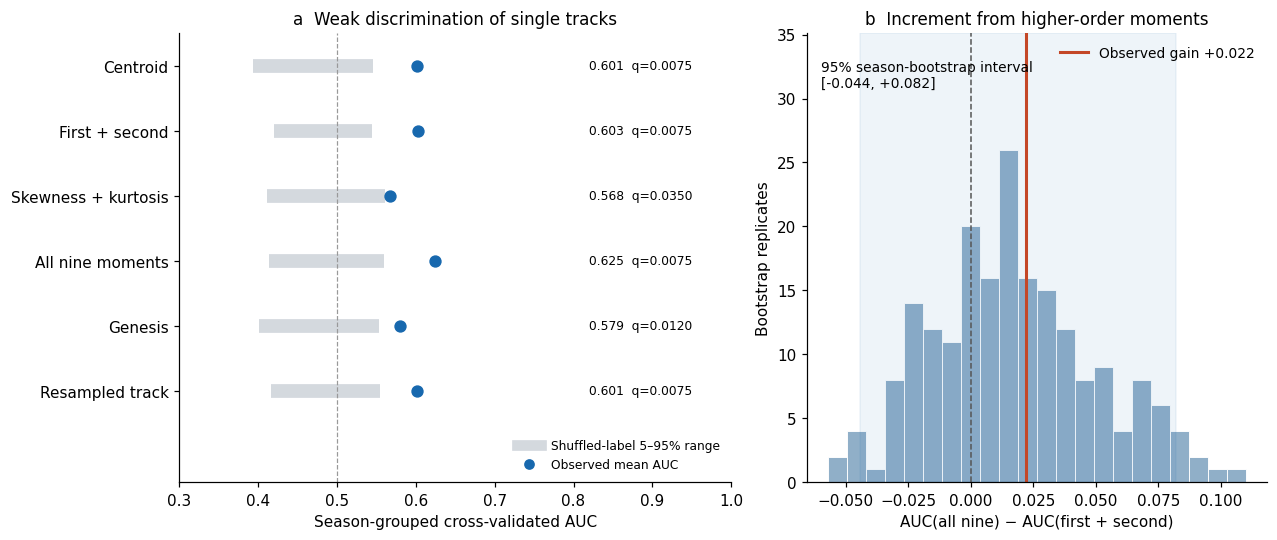

全部九矩的平均 AUC 为 **0.625**；整季标签置换的 5–95% 范围为 [0.414, 0.560]，BH q=0.0075。在一二阶矩（AUC 0.603）上加入偏度与峰度，观察增益为 **+0.022**，配对季节 bootstrap 95% 区间为 **[-0.044, +0.082]**。

In [8]:
classification_table, gains, gain = aa.classification(storms, features,
                                                    splits=10, permutations=199, bootstrap=200)
display(classification_table.round(4))
display(pd.DataFrame([gain]).round(4))
aa.fig_classification(classification_table, gains, gain)
all9 = classification_table.set_index('features').loc['All nine moments']
low = classification_table.set_index('features').loc['First + second']
display(Markdown(f"全部九矩的平均 AUC 为 **{all9.auc:.3f}**；整季标签置换的 5–95% 范围为 "
                 f"[{all9.null_05:.3f}, {all9.null_95:.3f}]，BH q={all9.q_bh:.4f}。"
                 f"在一二阶矩（AUC {low.auc:.3f}）上加入偏度与峰度，观察增益为 **{gain['delta']:+.3f}**，"
                 f"配对季节 bootstrap 95% 区间为 **[{gain['ci_low']:+.3f}, {gain['ci_high']:+.3f}]**。"))

**图 7｜可检测的群体信息与有限的个体区分能力。** a 中蓝点为 10 次整年分折的平均 AUC，灰条为完整模型在 199 次整季标签置换下的 5–95% 范围，**灰条不是观察 AUC 的置信区间**。q 值对六组特征进行 BH 校正。b 为加入高阶矩后的配对季节 bootstrap 增益分布，红线标出观察增益，淡色带为 95% 区间。

这一步把“存在 ENSO 相关信息”与“可以准确判断单条路径属于哪种年份”分开。AUC 约 0.63 对应有限的区分能力。高阶矩的增益若区间跨越零，则目前的季节样本尚不能把这项增益与季节间变异清楚区分；这与高阶矩本身含有一些信息并不矛盾。

## 9. 讨论：把数量、构成和个体信息放回同一条逻辑链

季节指标首先建立了活动强弱的关联：拉尼娜与厄尔尼诺并非只在地图颜色上不同，年均风暴数量、ACE 和美国登陆风暴数也呈系统差异。路径类型进一步说明差异在空间上并不均匀，墨西哥湾—加勒比型的发生率变化贡献了较大部分的数量差。

质心分解解释了为什么数量变化会呈现为地理位移。偏西类型在总体中的权重下降，使全体质心向东移动；类内位置变化则为北移贡献了较大的分量。该解释来自对同一组路径的代数分解和整季检验，不需要预设一种固定的“厄尔尼诺路径形状”。偏度与峰度描述更细的分布形状，但它们在质心和离散程度之上的额外判别价值没有得到稳定支持。

这些空间结果与 ENSO 调整大西洋热带气旋环境的物理背景相吻合 [1]。本分析没有直接加入风切变、湿度或大西洋海温场，因此把结果解释为 **ENSO 相关的季节风险分布及其组成变化**。进一步区分生成环境、引导气流和海温的贡献，需要把这些环境变量纳入同一季节框架。

推断范围由数据和设计界定：主对比包含 29 个非中性季节；坐标快照保留至 0.1°；美国登陆采用上述定位点和多边形规则；去趋势分析只检验线性时间项。主分析的整年置换仍依赖跨年份可交换性，未直接拟合多年代振荡或跨年相关结构。时期、类型数和逐季剔除结果用于评估这些设定下结论的稳定部分。

### 结论与证据对应

下表由本次执行的结果填充。它把结论限定到实际检验对象，同时保留“太平洋变暖，大西洋如何响应”的完整叙述。

In [9]:
lon = decomposition.query('axis == "longitude"').set_index('component')
lat = decomposition.query('axis == "latitude"').set_index('component')
claims = pd.DataFrame([
    {'结论': 'ENSO 位相与季节活动强弱相关', '证据': f"风暴数差 {activity.iloc[0].delta_nina_minus_nino:.2f}/年；Holm p={activity.iloc[0].p_holm:.4f}", '图表': '图 1–2 / seasonal_contrasts.csv'},
    {'结论': '墨西哥湾—加勒比型贡献较大部分的数量差', '证据': f"该类型差 {type_rates.iloc[0].delta_nina_minus_nino:.2f}/年；Holm p={type_rates.iloc[0].p_holm:.4f}", '图表': '图 3 / type_rates.csv'},
    {'结论': '东移主要由类型构成变化解释', '证据': f"总东移 {lon.loc['total','estimate']:.2f}°；构成项 {lon.loc['type_mix','estimate']:.2f}°", '图表': '图 4–5 / centroid_decomposition.csv'},
    {'结论': '北移含类内位置变化，证据随类型分辨率变化', '证据': f"总北移 {lat.loc['total','estimate']:.2f}°；类内项 {lat.loc['within_type','estimate']:.2f}°", '图表': '图 4–5 / decomposition_robustness.csv'},
    {'结论': '单条路径的 ENSO 区分能力有限', '证据': f"九矩 AUC={all9.auc:.3f}，BH q={all9.q_bh:.4f}", '图表': '图 6–7 / classification.csv'},
    {'结论': '高阶矩的额外增益尚未建立', '证据': f"ΔAUC={gain['delta']:+.3f}；95% CI [{gain['ci_low']:+.3f},{gain['ci_high']:+.3f}]", '图表': '图 7 / auc_gain_bootstrap.csv'}
])
display(claims)
aa.write_table(claims, 'claim_evidence')
display(Markdown(f"**综合结论。** 在 1966–2025 年的北大西洋记录中，拉尼娜季节比厄尔尼诺季节平均多 "
                 f"{activity.iloc[0].delta_nina_minus_nino:.2f} 条风暴，较大的数量差来自墨西哥湾—加勒比型路径。"
                 f"厄尔尼诺年的总体质心向东偏移 {lon.loc['total','estimate']:.2f}°，其中类型构成贡献 "
                 f"{lon.loc['type_mix','estimate']:.2f}°；向北偏移 {lat.loc['total','estimate']:.2f}°，"
                 f"其中类内位置变化贡献 {lat.loc['within_type','estimate']:.2f}°。"
                 f"这些群体差异对应的是季节风险分布的变化，而单条路径的区分能力仍有限（AUC {all9.auc:.3f}）。"
                 "因此，理解 ENSO 的路径响应，应先看哪些风暴出现、它们在哪里活动，再讨论更高阶的形状特征。"))

# Internal consistency checks link the narrative to the data and the decomposition identity.
assert np.allclose(type_rates.delta_nina_minus_nino.sum(), activity.iloc[0].delta_nina_minus_nino)
for t in [lon, lat]:
    assert np.isclose(t.loc['total','estimate'], t.loc['type_mix','estimate']+t.loc['within_type','estimate'])
assert gain['seasons'] == 29 and gain['storms'] == 391
assert abs(all9.auc - .625) < .003  # cross-check against the atlas baseline, not a fitted target
assert len(list(aa.FIG.glob('fig*.png'))) == 7
assert len(list(aa.FIG.glob('fig*.pdf'))) == 7
assert len(list(aa.FIG.glob('fig*.svg'))) == 7
print('Consistency checks passed; all figures and tables were generated in this execution.')

,结论,证据,图表
0,ENSO 位相与季节活动强弱相关,风暴数差 5.14/年；Holm p=0.0165,图 1–2 / seasonal_contrasts.csv
1,墨西哥湾—加勒比型贡献较大部分的数量差,该类型差 3.60/年；Holm p=0.0008,图 3 / type_rates.csv
2,东移主要由类型构成变化解释,总东移 6.66°；构成项 5.85°,图 4–5 / centroid_decomposition.csv
3,北移含类内位置变化，证据随类型分辨率变化,总北移 2.22°；类内项 1.58°,图 4–5 / decomposition_robustness.csv
4,单条路径的 ENSO 区分能力有限,九矩 AUC=0.625，BH q=0.0075,图 6–7 / classification.csv
5,高阶矩的额外增益尚未建立,"ΔAUC=+0.022；95% CI [-0.044,+0.082]",图 7 / auc_gain_bootstrap.csv


**综合结论。** 在 1966–2025 年的北大西洋记录中，拉尼娜季节比厄尔尼诺季节平均多 5.14 条风暴，较大的数量差来自墨西哥湾—加勒比型路径。厄尔尼诺年的总体质心向东偏移 6.66°，其中类型构成贡献 5.85°；向北偏移 2.22°，其中类内位置变化贡献 1.58°。这些群体差异对应的是季节风险分布的变化，而单条路径的区分能力仍有限（AUC 0.625）。因此，理解 ENSO 的路径响应，应先看哪些风暴出现、它们在哪里活动，再讨论更高阶的形状特征。

Consistency checks passed; all figures and tables were generated in this execution.


## 10. 复现信息与参考文献

- `atlas_analysis.py`：本 Notebook 使用的统计和绘图函数，包括固定随机种子、分折规则和校正方法。
- `data/atlas_snapshot.json`、`data/atlantic_land.geojson`、`data/manifest.json`：输入快照、海岸线及校验和。
- `results/*.csv`：本次运行的全部结果表，包括置换零分布和 bootstrap 增益样本；`results/environment.json` 记录运行版本。
- `figures/fig01–fig07`：每张图均输出 300 dpi PNG、PDF 和 SVG。正文中的图片由运行代码直接显示，不依赖网页截图。
- `scripts/run_research_notebook.py`：从空内核顺序执行所有代码单元，成功后保存带输出的 Notebook；不复用旧单元输出。

与网页的对应：数据、主要效应定义、默认时期和观察 AUC 保持一致。本 Notebook 增加了显式置信区间、多重比较校正和更多置换；因此 p 值以及增益区间不要求与网页按较少重采样得到的数值逐位相同。

1. **NOAA CPC.** *ENSO FAQ*: ENSO 与大西洋飓风环境的物理联系。[官方说明](https://www.cpc.ncep.noaa.gov/products/analysis_monitoring/ensostuff/ensofaq.shtml)。
2. **Nakamura, J., Lall, U., Kushnir, Y. & Camargo, S. J. (2009).** Classifying North Atlantic Tropical Cyclone Tracks by Mass Moments. *Journal of Climate*, **22**, 5481–5494. [doi:10.1175/2009JCLI2828.1](https://doi.org/10.1175/2009JCLI2828.1)。
3. **Knapp, K. R., Kruk, M. C., Levinson, D. H., Diamond, H. J. & Neumann, C. J. (2010).** The International Best Track Archive for Climate Stewardship (IBTrACS): Unifying Tropical Cyclone Data. *Bulletin of the American Meteorological Society*, **91**, 363–376. [doi:10.1175/2009BAMS2755.1](https://doi.org/10.1175/2009BAMS2755.1)；[NOAA NCEI 数据页](https://www.ncei.noaa.gov/products/international-best-track-archive)。
4. **NOAA CPC.** Oceanic Niño Index (ERSSTv5), [数据文件](https://www.cpc.ncep.noaa.gov/data/indices/oni.ascii.txt)。本分析使用快照中的历史 ASO 序列，不使用 2026 年的未结束飓风季作为结果样本。
5. **Natural Earth / world-atlas.** 1:50m land polygons，[Natural Earth](https://www.naturalearthdata.com/)；[world-atlas v2.0.2](https://github.com/topojson/world-atlas/tree/v2.0.2)。海岸线仅作制图背景。

数据快照保存日期：2026-10-19。固定输入的版本和 SHA-256 见 manifest；原始下载来源若发生更新，应建立新的快照后另行比较结果。